<a href="https://colab.research.google.com/github/aHawkins63/Feature-Engineering/blob/main/ARIMA_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_554/1896831772.py:13: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('shampoo-1.csv', header=0, index_col=0, parse_dates=True, date_parser=parser).squeeze('columns')


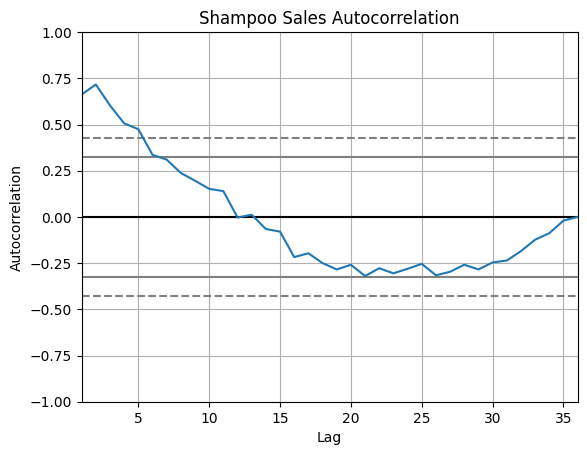

In [5]:
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from pandas import DataFrame
from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from math import sqrt

def parser(x):
	return datetime.strptime('190'+x, '%Y-%m')

series = read_csv('shampoo-1.csv', header=0, index_col=0, parse_dates=True, date_parser=parser).squeeze('columns')
autocorrelation_plot(series)
pyplot.title('Shampoo Sales Autocorrelation')
pyplot.show()

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -198.485
Date:                Thu, 27 Oct 2022   AIC                            408.969
Time:                        07:15:13   BIC                            418.301
Sample:                    01-31-1901   HQIC                           412.191
                         - 12-31-1903                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9014      0.247     -3.647      0.000      -1.386      -0.417
ar.L2         -0.2284      0.268     -0.851      0.395      -0.754       0.298
ar.L3          0.0747      0.291      0.256      0.7

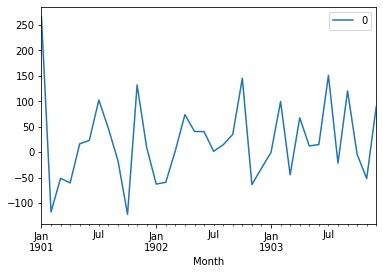

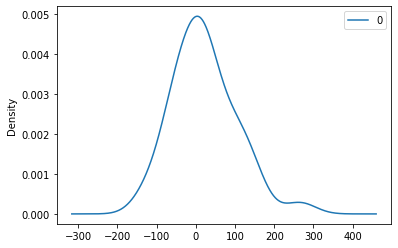

                0
count   36.000000
mean    21.936144
std     80.774430
min   -122.292030
25%    -35.040859
50%     13.147219
75%     68.848286
max    266.000000


In [ ]:
series.index = series.index.to_period('M')
# fit model
model = ARIMA(series, order=(5,1,0))
model_fit = model.fit()
# summary of fit model
print(model_fit.summary())
# line plot of residuals
residuals = DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
# density plot of residuals
residuals.plot(kind='kde')
pyplot.show()
# summary stats of residuals
print(residuals.describe())

predicted=343.272180, expected=342.300000
predicted=293.329674, expected=339.700000
predicted=368.668956, expected=440.400000
predicted=335.044741, expected=315.900000
predicted=363.220222, expected=439.300000
predicted=357.645324, expected=401.300000
predicted=443.047835, expected=437.400000
predicted=378.365674, expected=575.500000
predicted=459.415021, expected=407.600000
predicted=526.890876, expected=682.000000
predicted=457.231274, expected=475.300000
predicted=672.914943, expected=581.300000
predicted=531.541449, expected=646.900000
Test RMSE: 89.021


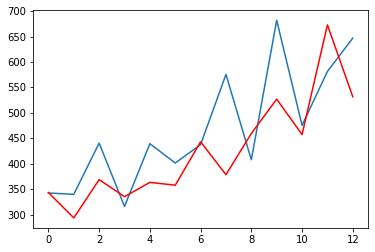

In [ ]:
#series.index = series.index.to_period('M')
# split into train and test sets
X = series.values
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()
# walk-forward validation
for t in range(len(test)):
	model = ARIMA(history, order=(5,1,0))
	model_fit = model.fit()
	output = model_fit.forecast()
	yhat = output[0]
	predictions.append(yhat)
	obs = test[t]
	history.append(obs)
	print('predicted=%f, expected=%f' % (yhat, obs))
# evaluate forecasts
rmse = sqrt(mean_squared_error(test, predictions))
print('Test RMSE: %.3f' % rmse)
# plot forecasts against actual outcomes
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

Beer Test RMSE: 579.022


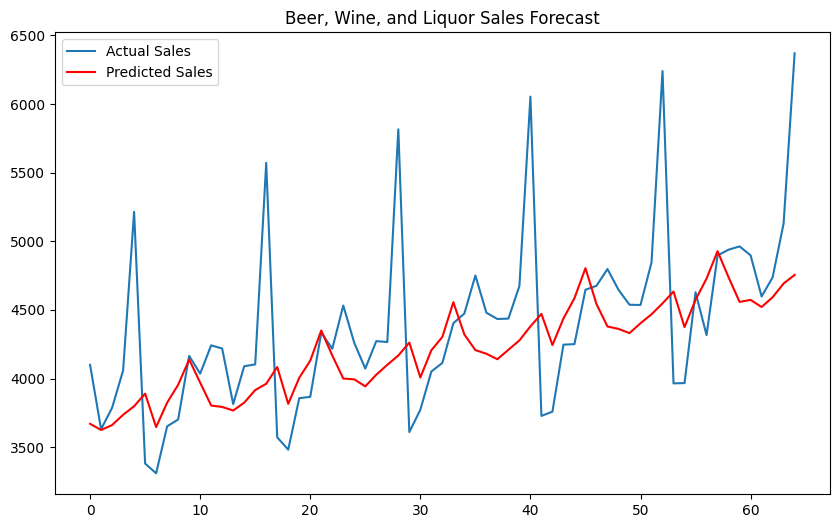

In [6]:
beer_series = read_csv('BeerWineLiquor-1.csv', header=0, index_col=0, parse_dates=True).squeeze('columns')

X_beer = beer_series.values
size_beer = int(len(X_beer) * 0.8)
train_beer, test_beer = X_beer[0:size_beer], X_beer[size_beer:len(X_beer)]
history_beer = [x for x in train_beer]
predictions_beer = list()

for t in range(len(test_beer)):
	model_beer = ARIMA(history_beer, order=(5,1,1))
	model_fit_beer = model_beer.fit()
	output_beer = model_fit_beer.forecast()
	yhat_beer = output_beer[0]
	predictions_beer.append(yhat_beer)
	obs_beer = test_beer[t]
	history_beer.append(obs_beer)

rmse_beer = sqrt(mean_squared_error(test_beer, predictions_beer))
print('Beer Test RMSE: %.3f' % rmse_beer)

pyplot.figure(figsize=(10,6))
pyplot.plot(test_beer, label='Actual Sales')
pyplot.plot(predictions_beer, color='red', label='Predicted Sales')
pyplot.title('Beer, Wine, and Liquor Sales Forecast')
pyplot.legend()
pyplot.show()